In [1]:
import os
import numpy as np
import pyccl as ccl
import healpy as hp
import pymaster as nmt
import matplotlib.pyplot as plt
import libconf
# from scipy.integrate import simps
from scipy.integrate import simpson
from astropy.io import fits

import camb
from camb import model, initialpower
from __future__ import print_function
import treecorr
import fitsio
import time
import pprint
import pandas as pd
import camb
from camb import model
from camb.sources import SplinedSourceWindow
from scipy.special import erf



os.environ["LD_LIBRARY_PATH"] = "/home/roger02/Healpix_3.83/lib:" + os.environ.get("LD_LIBRARY_PATH", "")

In [11]:
seed = 1100
dirname_out = f'./variance/colore_run_seed_{seed}'
# os.system(f'mkdir -p {dirname_out}')

# Constant background temperature T_HI = 0.05 mK
zs = np.arange(0.0, 1.5, 0.001)
tz = 0.05 * np.ones_like(zs)
bz = np.ones_like(zs)
np.savetxt(f'{dirname_out}/bias.txt', np.transpose([zs, bz]))

nu_ref = 1420.
nu0 = nu_ref / (1+1.0)
nu1 = nu_ref / (1+0.6)
n_nu = 250
nu_arr = np.linspace(nu0, nu1, n_nu+1)
#nu_arr = np.arange(nu0, nu1, 5) # every 20 MHz
# nu_arr = np.array([nu0, nu1]) 

# print(tz, nu_arr)

np.savetxt(f'{dirname_out}/tz.txt', np.transpose([zs, tz]))
np.savetxt(f'{dirname_out}/nuTable.txt', np.transpose([nu_arr[:-1], nu_arr[1:]]))

def dndz_des_alonso(zi, amp=22.357, alpha=1.044, z0=0.568, beta=1.742):
    """
    in deg⁻2
    """
    return amp*(zi/z0)**alpha*np.exp(-(zi/z0)**beta)*3600

def W_err(z,zc,sz,smooth):
    return (erf((zc+sz-z)/(np.sqrt(2)*smooth))-erf((zc-sz-z)/(np.sqrt(2)*smooth)))/2


nz = dndz_des_alonso(zs)* W_err(zs,0.8,0.2,0.01)
np.savetxt(f'{dirname_out}/dndz.txt', np.transpose([zs, nz]))

h0=0.6774
H0=h0*100
Om=0.31
OL=1-Om
Ob=0.05
Ocdm=Om-Ob
As = 2.142e-9
ns = 0.967

def get_pk(z_in):
    """Returns k, Pk, f and sigma8
    in h units"""
    #Set up the fiducial cosmology
    pars = camb.CAMBparams()
    #Set cosmology
    pars.set_cosmology(H0=H0, ombh2=Ob*h0**2, omch2=Ocdm*h0**2,omk=0,mnu=0)
    pars.set_dark_energy() #LCDM (default)
    pars.InitPower.set_params(ns=ns, r=0, As=As)
    pars.set_matter_power(redshifts=[z_in], kmax=2.0)
    pars.NonLinear = model.NonLinear_none
    results = camb.get_results(pars)
    kh, z, pk = results.get_matter_power_spectrum(minkh=1e-4, maxkh=2.0, npoints = 500)
    
    s8 = results.get_sigma8()
    f = results.get_fsigma8()/s8
    
    return kh, pk[0], f[0], s8[0]

k_h, pk_h, f, s8 = get_pk(0)

csm = {'omega_M': Om,
       'omega_B': Ob,
       'omega_L': OL,
       'h': h0,
       'w': -1.0,
       'ns': ns,
       'sigma_8': s8}

cosmo = ccl.Cosmology(Omega_c=csm['omega_M']-csm['omega_B'],
                      Omega_b=csm['omega_B'],
                      h=csm['h'],
                      sigma8=csm['sigma_8'],
                      n_s=csm['ns'],
                      transfer_function='eisenstein_hu')

np.savetxt(f'{dirname_out}/pk.txt', np.transpose([k_h, pk_h]))


# n_grid = 256
n_grid = 2048
#n_grid = 1024


config = {}
config['global'] = {'prefix_out': 'colore_seed_1010',
                    'output_format': 'FITS',
                    'output_density': False, #FALSE
                    'pk_filename': f'./pk.txt',
                    'z_min': 0.001,
                    'z_max': 1.1,
                    'seed': seed,
                    'write_pred': False,
                    'just_write_pred': True}
config['field_par'] = {'r_smooth': 1.,
                       'smooth_potential': True,
                       'n_grid': n_grid,
                       'dens_type': 1,
                       'lpt_buffer_fraction': 0.6,
                       'lpt_interp_type': 1,
                       'output_lpt': 0}
config['cosmo_par'] = csm
config['srcs1'] = {'nz_filename': f'./dndz.txt',
                   'bias_filename': f'./bias.txt',
                   'include_lensing': True,
                   'store_skewers': False}
config['imap1'] = {'tbak_filename': f'./tz.txt',
                   'bias_filename': f'./bias.txt',
                   'freq_list': f'./nuTable.txt',
                   'freq_rest': 1420.0,
                   'nside': 1024}
with open(f'{dirname_out}/params.cfg', 'w') as configfile:
    libconf.dump(config, configfile)

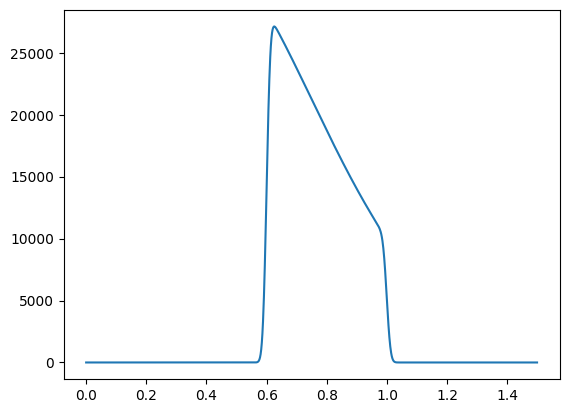

In [6]:
plt.plot(zs, nz)

In [2]:
from astropy.io import fits
header = fits.open('./variance/colore_run_seed_1000/colore_seed_1000_srcs_s1_0.fits')[1].header
header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional binary table                     
NAXIS1  =                   40 / width of table in bytes                        
NAXIS2  =             19534672 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group (required keyword)              
TFIELDS =                   10 / number of fields in each row                   
TTYPE1  = 'TYPE    '           / label for field   1                            
TFORM1  = '1J      '           / data format of field: 4-byte INTEGER           
TUNIT1  = 'NA      '           / physical unit of field                         
TTYPE2  = 'RA      '           / label for field   2                            
TFORM2  = '1E      '        